In [13]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [15]:
"""
Loading and cleaning the data:
 - column names are lowercased, 
 - spaces are replaced with underscores, 
 - totalcharges is converted to numbers with errors='coerce' 
 - and the missing values are filled with 0, and the target is turned into 0/1:
"""
df = pd.read_csv('../../03-Classification/notes/data-week-3.csv')

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

# df.churn = (df.churn == 'yes').astype(int)
df.churn = df.churn.astype(str).str.lower().str.strip().isin(['yes', '1']).astype(int)

In [16]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

In [17]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

In [18]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression()

model.fit(X_train, y_train)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [19]:
"""
- Then we split the data into train, validation and test: 60% for training, 20% for validation and 20% for test. 
- We do it in two steps - first split off the test set, then split the rest - and we use random_state=1 so the shuffle is reproducible:
"""
# from sklearn.model_selection import train_test_split

# df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
# df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

'\n- Then we split the data into train, validation and test: 60% for training, 20% for validation and 20% for test. \n- We do it in two steps - first split off the test set, then split the rest - and we use random_state=1 so the shuffle is reproducible:\n'

In [20]:
# Use the scikit-learn DictVectorizer
# from sklearn.feature_extraction import DictVectorizer

# dv = DictVectorizer(sparse=False)

# train_dict = df_train[categorical + numerical].to_dict(orient='records')
# X_train = dv.fit_transform(train_dict)

# dv.get_feature_names_out()

In [21]:
# Training the Logistic Regression model
# from sklearn.linear_model import LogisticRegression

# model = LogisticRegression(solver='lbfgs')
# # solver='lbfgs' is the default solver in newer version of sklearn
# # for older versions, you need to specify it explicitly
# model.fit(X_train, y_train)

# y_pred = model.predict_proba(X_val)[:, 1]
# churn_decision = (y_pred >= 0.5)
# (y_val == churn_decision).mean()

In [22]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

np.float64(0.801277501774308)

In [23]:
len(y_val)

1409

In [24]:
from sklearn.metrics import accuracy_score

accuracy_score(y_val, y_pred >= 0.5)

0.801277501774308

In [25]:
# Checkng different thresholds
thresholds = np.linspace(0, 1, 21)

scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f' % (t, score))
    scores.append(score)

0.00 0.274
0.05 0.509
0.10 0.598
0.15 0.664
0.20 0.707
0.25 0.737
0.30 0.759
0.35 0.766
0.40 0.780
0.45 0.793
0.50 0.801
0.55 0.798
0.60 0.797
0.65 0.784
0.70 0.765
0.75 0.744
0.80 0.730
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


In [26]:
# The Dummy model
from collections import Counter

Counter(y_pred >= 1.0)

Counter({np.False_: 1409})

In [27]:
1 - y_val.mean() # <----- baseline when assuming no customer will churn/No Model

np.float64(0.7260468417317246)

In [28]:
# Confusion table
# Computing the counts for each customer into one of four categories: True Negative | False Negative | True Positive | False Positive
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [29]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()

fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

In [30]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[915, 108],
       [172, 214]])

In [31]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.08],
       [0.12, 0.15]])

In [32]:
# ROC (Receiver Operating Characteristic) Curves
tpr = tp / (tp + fn)
fpr = fp / (fp + tn)

In [33]:
# TPR and FPR for all thresholds
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

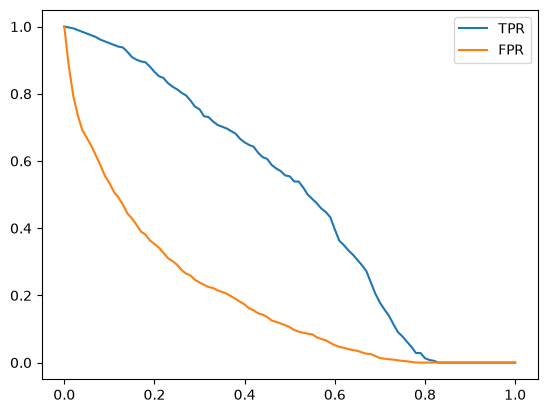

In [34]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

In [35]:
# The Random model
np.random.seed(1)
y_rand = np.random.uniform(0, 1, size=len(y_val))

In [36]:
# The Ideal model
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()

y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal_pred = np.linspace(0, 1, len(y_val))

In [37]:
accuracy_score(y_ideal, y_ideal_pred >= 0.726)

1.0

NameError: name 'df_ideal' is not defined

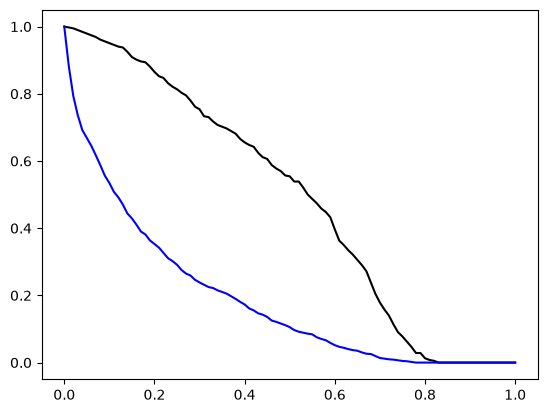

In [38]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR', color='black')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR', color='blue')

plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR ideal')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR ideal')

plt.legend()

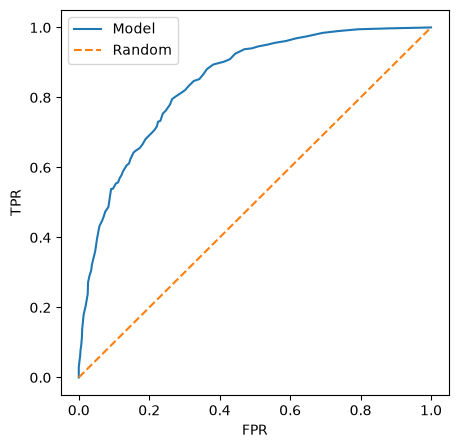

In [39]:
plt.figure(figsize=(5, 5))

plt.plot(df_scores.fpr, df_scores.tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

In [40]:
# ROC Curves with scikit-learn
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_val, y_pred)

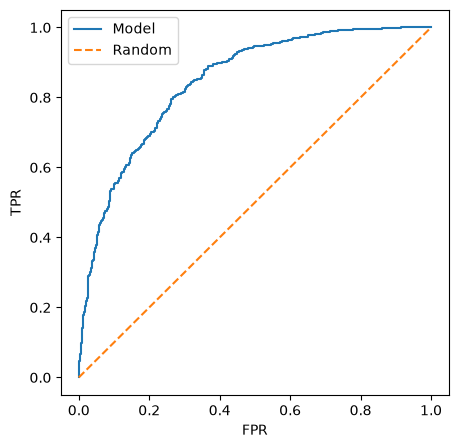

In [41]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

In [42]:
# Compute the ROC AUC - Area Under Curve
from sklearn.metrics import auc

auc(fpr, tpr)

0.8445038720820102

In [43]:
# compute the ROC curve and area in one step
from sklearn.metrics import roc_auc_score

roc_auc_score(y_val, y_pred)

0.8445038720820102

In [44]:
# split the predictions into scores of negatives and positives
neg = y_pred[y_val == 0]
neg


array([0.00786347, 0.20992803, 0.2237105 , ..., 0.10417002, 0.29779033,
       0.15014869], shape=(1023,))

In [45]:
pos = y_pred[y_val == 1]
pos

array([0.56112288, 0.59063094, 0.4837482 , 0.72950829, 0.07271828,
       0.69467309, 0.242221  , 0.68243361, 0.22362329, 0.66934217,
       0.45523129, 0.37245308, 0.15189388, 0.591306  , 0.75547998,
       0.1532364 , 0.43516344, 0.28301368, 0.07769171, 0.20247408,
       0.64500491, 0.42542184, 0.6641118 , 0.56807564, 0.53762684,
       0.45687566, 0.49389462, 0.3252516 , 0.57404126, 0.33734029,
       0.61608186, 0.73529421, 0.73933039, 0.59670589, 0.67993196,
       0.76442182, 0.09655518, 0.19784189, 0.52147377, 0.56910182,
       0.45186805, 0.46340866, 0.73946024, 0.38443694, 0.68467854,
       0.42746465, 0.74341083, 0.27526363, 0.54378428, 0.58333509,
       0.14199704, 0.53405553, 0.77662177, 0.45411631, 0.67852849,
       0.75737511, 0.01262553, 0.36234625, 0.77098678, 0.57425707,
       0.6826321 , 0.25616074, 0.35933846, 0.68907427, 0.19915782,
       0.67991879, 0.66823172, 0.30968343, 0.67030663, 0.30987103,
       0.50857379, 0.27605559, 0.41193609, 0.42820067, 0.50453

In [46]:
# repeatedly draw one score from each group at random and count how often the positive one wins:

import random

n = 100000
success = 0 

for i in range(n):
    pos_ind = random.randint(0, len(pos) - 1)
    neg_ind = random.randint(0, len(neg) - 1)

    if pos[pos_ind] > neg[neg_ind]:
        success = success + 1

success / n

0.84344

In [47]:
# The same comparison in vectorized NumPy: draw 50000 random indices into each group at once, 
# compare the scores element-wise, and take the mean of the resulting boolean array:
n = 50000

np.random.seed(1)
pos_ind = np.random.randint(0, len(pos), size=n)
neg_ind = np.random.randint(0, len(neg), size=n)

(pos[pos_ind] > neg[neg_ind]).mean()

np.float64(0.8466)

In [48]:
# The Area under the ROC curves can tell us how good is our model with a single value. 
# The AUROC of a random model is 0.5, while for an ideal one is 1.

# In other words, AUC can be interpreted as the probability that a randomly selected positive example 
# has a greater score than a randomly selected negative example.

In [49]:
# Cross-validation: Cross-validation is a way to evaluate the same model on different subsets of the data, 
# so we get not just one number but an average and a spread - and we can use it for parameter tuning: 
# selecting the best parameters for the model.

In [50]:
# Parameter tuning
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [51]:
# predict applies the saved vectorizer and model to any dataframe and returns the churn probabilities:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [52]:
# K-fold cross-validation
# The idea of k-fold cross-validation: split the full training dataset into k partitions (folds). Train the model on k-1 folds, 
# evaluate on the remaining one. Repeat k times, so every fold serves as the validation set once, and average the scores.

from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [53]:
!pip install tqdm


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


In [54]:
# kfold.split(df_full_train) is a Python generator: each call to next yields the next split as two arrays of row indices - the indices to train on and the indices to validate on. 
# We slice the dataframe with iloc, train, predict and score with AUC:

from tqdm.auto import tqdm

n_splits = 5

for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.churn.values
        y_val = df_val.churn.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C=0.001 0.825 +- 0.009


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproc

C=0.01 0.840 +- 0.008


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproc

C=0.1 0.842 +- 0.007


... (4 outputs left out)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproc

C=5 0.842 +- 0.007


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproc

C=10 0.842 +- 0.007


In [55]:
scores

[0.8447064549300971,
 0.8450763971659383,
 0.8333895243829019,
 0.8348488360938799,
 0.8516441278905589]

In [56]:
# Training the final model (after selecting C)
C=1.0
dv, model = train(df_full_train, df_full_train.churn.values, C)
y_pred = predict(df_test, dv, model)

auc = roc_auc_score(y_test, y_pred)
auc

0.8584032088573997

In [57]:
C

1.0

In [58]:
# When to use Cross-Validation
  # If the dataset is large, a single hold-out validation split is usually enough - it is faster, and the estimate is already stable.
  # If the dataset is small, or we want to know how stable the model is across different splits, 
  # cross-validation is worth the extra computation. More folds give a better estimate but take longer to compute.

In [59]:
# Summary
# In this final lesson of module 4 we wrap up everything we learned about evaluating a binary classifier.
# This week was about different metrics to evaluate the churn model: accuracy, the confusion table, 
# precision, recall, ROC curves (TPR, FPR, the random model, and the ideal model), ROC AUC, and cross-validation for parameter tuning.

In [60]:
# Model Deployment: Saving and loading the model with pickle lib
import pickle

output_file = f'model_C={C}.bin'

with open(output_file, 'wb') as f_out:
    pickle.dump((dv, model), f_out)

In [61]:
# Loading the model from a webservice
import pickle

with open('model_C=1.0.bin', 'rb') as f_in:
    dv, model = pickle.load(f_in)

In [63]:
import requests

url = 'http://localhost:9696/predict'

customer = {
    "gender": "female",
    "seniorcitizen": 0
}

response = requests.post(url, json=customer).json()
print(response)

if response['churn'] == True:
    print('sending promo email to %s' % customer_id)
else:
    print('not sending promo email to %s' % customer_id)

ConnectionError: HTTPConnectionPool(host='localhost', port=9696): Max retries exceeded with url: /predict (Caused by NewConnectionError("HTTPConnection(host='localhost', port=9696): Failed to establish a new connection: [Errno 111] Connection refused"))